In [1]:
import pandas as pd
import numpy as np

timetable_by_course_code = pd.read_excel('Data/Timetable_by_course_code_2025_26.xlsx')
timetable_by_course_code.rename(columns={'Module.Host Key': 'Module'}, inplace=True)
timetable_by_course_code['Code'] = timetable_by_course_code['Description'].str.split(' ').str[0]
timetable_by_course_code['Start'] = pd.to_timedelta(timetable_by_course_code['Start'] + ':00')
timetable_by_course_code['End'] = pd.to_timedelta(timetable_by_course_code['End'] + ':00')
timetable_by_course_code['Duration'] = timetable_by_course_code['End'] - timetable_by_course_code['Start']
timetable_by_course_code['AT'] =  timetable_by_course_code['AT Weeks'].notna() & (timetable_by_course_code['AT Weeks'] != '')
timetable_by_course_code['WT'] =  timetable_by_course_code['WT Weeks'].notna() & (timetable_by_course_code['WT Weeks'] != '')
timetable_by_course_code['AT_week_count'] = timetable_by_course_code['AT Weeks'].apply(lambda x: len(str(x).split(',')) if pd.notna(x) and x != '' else 0)
timetable_by_course_code['WT_week_count'] = timetable_by_course_code['WT Weeks'].apply(lambda x: len(str(x).split(',')) if pd.notna(x) and x != '' else 0)
timetable_by_course_code.head()

,Department Name,Module,Description,Type,Group,Scheduled Day,Start,End,AT Weeks,WT Weeks,ST Weeks,Location,Staff,Code,Duration,AT,WT,AT_week_count,WT_week_count
0,AC00 - Department of Accounting,AC102,AC102 Elements of Financial Accounting,LECTURE,1,Mon,0 days 09:00:00,0 days 11:00:00,"1,2,3,4,5,6,7,8,9,10",NaN,NaN,PT,"KAMATH, DR SAIPRIYA",AC102,0 days 02:00:00,True,False,10,0
1,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,CLASS,1,Mon,0 days 11:00:00,0 days 12:00:00,"2,3,4,5,6,7,8,9,11",NaN,NaN,MAR.1.07,"CONSTANTINOU, MRS CHRISOULLA",AC102.A,0 days 01:00:00,True,False,9,0
2,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,CLASS,1,Thu,0 days 09:00:00,0 days 10:00:00,10,NaN,NaN,MAR.1.07,"CONSTANTINOU, MRS CHRISOULLA",AC102.A,0 days 01:00:00,True,False,1,0
3,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,CLASS,2,Mon,0 days 12:00:00,0 days 13:00:00,"2,3,4,5,6,7,8,9,11",NaN,NaN,MAR.1.07,"CONSTANTINOU, MRS CHRISOULLA",AC102.A,0 days 01:00:00,True,False,9,0
4,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,CLASS,2,Wed,0 days 09:00:00,0 days 10:00:00,10,NaN,NaN,MAR.1.09,"CONSTANTINOU, MRS CHRISOULLA",AC102.A,0 days 01:00:00,True,False,1,0


In [2]:
timetable_by_course_code['Start'].unique()

<TimedeltaArray>
['0 days 09:00:00', '0 days 11:00:00', '0 days 12:00:00', '0 days 14:00:00',
 '0 days 10:00:00', '0 days 15:00:00', '0 days 17:00:00', '0 days 16:00:00',
 '0 days 13:00:00', '0 days 18:00:00', '0 days 12:30:00', '0 days 16:30:00',
 '0 days 15:30:00', '0 days 13:30:00', '0 days 10:30:00', '0 days 09:30:00',
 '0 days 11:30:00', '0 days 18:30:00', '0 days 08:00:00', '0 days 14:30:00',
 '0 days 17:30:00', '0 days 19:00:00', '0 days 07:00:00', '0 days 08:30:00',
 '0 days 17:15:00']
Length: 25, dtype: timedelta64[us]

In [3]:
timetable_by_course_code['Type'].unique()

<StringArray>
['LECTURE', 'CLASS', 'SEMINAR', 'WORKSHOP']
Length: 4, dtype: str

In [4]:
teaching_rooms = pd.read_excel('Data/Teaching_rooms_2025_26.xlsx', header=2)
teaching_rooms.head()

,Zone Name,Name,Host Key,Capacity,Suitability
0,CBG - Centre Building,Auditorium [200],CBG.B1.02,200,T/Teaching Room
1,CBG - Centre Building,CBG.1.02 [42],CBG.1.02,42,T/Teaching Room
2,CBG - Centre Building,CBG.1.03 [42],CBG.1.03,42,T/Teaching Room
3,CBG - Centre Building,CBG.1.04 [42],CBG.1.04,42,T/Teaching Room
4,CBG - Centre Building,CBG.1.05 [42],CBG.1.05,42,T/Teaching Room


In [5]:
groups = pd.read_excel('Data/Group Sizes.xlsx')
groups.rename(columns={"Group No.": "Group"}, inplace=True)
groups.head()

,Code,Group,Teaching Title,Department,NUMSTU
0,AC102,L,Elements of Financial Accounting,Department of Accounting,646
1,AC102.A,1,Elements of Financial Accounting,Department of Accounting,19
2,AC102.A,10,Elements of Financial Accounting,Department of Accounting,18
3,AC102.A,11,Elements of Financial Accounting,Department of Accounting,16
4,AC102.A,12,Elements of Financial Accounting,Department of Accounting,18


In [32]:
groups.shape

(5583, 5)

In [33]:
len(groups['Code'].unique())

1988

In [7]:
course_master_data = timetable_by_course_code[['Code', 'Type', 'Group', 'Department Name', 'Module', 'Description', 'Duration', 'AT', 'AT Weeks', 'WT', 'WT Weeks', 'Staff']].copy()
course_master_data['Group'] = course_master_data['Group'].astype(str)
course_master_data.loc[course_master_data['Type'] == 'LECTURE', 'Group'] = 'L'
course_master_data.loc[course_master_data['Type'] == 'WORKSHOP', 'Group'] = 'W'
course_master_data = pd.merge(course_master_data, groups[['Code', 'Group', 'NUMSTU']].copy(), on=['Code', 'Group'])
course_master_data['Department'] = course_master_data['Department Name'].str[:4]
course_master_data['Course_Level'] = course_master_data['Code'].str[2:3]
course_master_data['Program'] = course_master_data['Department'] + course_master_data['Course_Level']
course_master_data.head()

,Code,Type,Group,Department Name,Module,Description,Duration,AT,AT Weeks,WT,WT Weeks,Staff,NUMSTU,Department,Course_Level,Program
0,AC102,LECTURE,L,AC00 - Department of Accounting,AC102,AC102 Elements of Financial Accounting,0 days 02:00:00,True,"1,2,3,4,5,6,7,8,9,10",False,NaN,"KAMATH, DR SAIPRIYA",646,AC00,1,AC001
1,AC102.A,CLASS,1,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,True,"2,3,4,5,6,7,8,9,11",False,NaN,"CONSTANTINOU, MRS CHRISOULLA",19,AC00,1,AC001
2,AC102.A,CLASS,1,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,True,10,False,NaN,"CONSTANTINOU, MRS CHRISOULLA",19,AC00,1,AC001
3,AC102.A,CLASS,2,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,True,"2,3,4,5,6,7,8,9,11",False,NaN,"CONSTANTINOU, MRS CHRISOULLA",18,AC00,1,AC001
4,AC102.A,CLASS,2,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,True,10,False,NaN,"CONSTANTINOU, MRS CHRISOULLA",18,AC00,1,AC001


In [8]:
course_master_data['Department'].unique()

<StringArray>
['AC00', 'AN00', 'DS00', 'DV00', 'EC00', 'EH00', 'EU00', 'FM00', 'GI00',
 'GV00', 'GY00', 'HP00', 'HY00', 'IR00', 'LL00', 'LN00', 'LS00', 'MA00',
 'MC00', 'MG00', 'MY00', 'PB00', 'PH00', 'PP00', 'SO00', 'SP00', 'ST00']
Length: 27, dtype: str

In [9]:
course_master_data['Duration'].unique()

<TimedeltaArray>
['0 days 02:00:00', '0 days 01:00:00', '0 days 01:30:00', '0 days 03:00:00',
 '0 days 04:00:00', '0 days 00:30:00', '0 days 06:30:00', '0 days 05:30:00',
 '0 days 02:30:00', '0 days 00:15:00', '0 days 09:00:00', '0 days 08:00:00',
 '0 days 03:30:00', '0 days 06:00:00', '0 days 05:00:00', '0 days 04:30:00',
 '0 days 07:00:00']
Length: 17, dtype: timedelta64[us]

In [10]:
course_master_data['Course_Level'].unique()

array(['1', '2', '3', '4', '5', 'D', 'E'], dtype=object)

In [11]:
course_master_data[course_master_data['Duration'] == '0 days 00:30:00']

,Code,Type,Group,Department Name,Module,Description,Duration,AT,AT Weeks,WT,WT Weeks,Staff,NUMSTU,Department,Course_Level,Program
341,AN102,LECTURE,L,AN00 - Anthropology,AN102,AN102 Anthropology through Mixed Media,0 days 00:30:00,True,3,False,NaN,"LONG, DR NICK",40,AN00,1,AN001
489,AN395,LECTURE,L,AN00 - Anthropology,AN395,AN395 Digital Anthropology,0 days 00:30:00,False,NaN,True,4,"LONG, DR NICK",45,AN00,3,AN003
613,AN495,LECTURE,L,AN00 - Anthropology,AN495,AN495 Digital Anthropology,0 days 00:30:00,False,NaN,True,4,"LONG, DR NICK",31,AN00,4,AN004
1907,EC307,LECTURE,L,EC00 - Economics,EC307,EC307 Development Economics,0 days 00:30:00,False,NaN,True,"1,2,3,4,5,7,8,9,10,11","BURGESS, PROF ROBIN",186,EC00,3,EC003
2167,EC330,LECTURE,L,EC00 - Economics,EC330,EC330 Environmental Economics,0 days 00:30:00,False,NaN,True,"1,2,3,4,5,7,8,9,10","BURGESS, PROF ROBIN",26,EC00,3,EC003


In [12]:
course_master_data[course_master_data['Course_Level'].isin(['D', 'E'])]

,Code,Type,Group,Department Name,Module,Description,Duration,AT,AT Weeks,WT,WT Weeks,Staff,NUMSTU,Department,Course_Level,Program
5907,HYDIS,LECTURE,L,HY00 - International History,HYDIS,HYDIS HY300 Dissertation - year 2 meetings,0 days 01:00:00,False,NaN,True,3,"ALVANDI, DR ROHAM",59,HY00,D,HY00D
5908,HYDIS,LECTURE,L,HY00 - International History,HYDIS,HYDIS HY300 Dissertation - year 2 meetings,0 days 01:00:00,False,NaN,True,4,"ALVANDI, DR ROHAM",59,HY00,D,HY00D
7873,LSE100A,SEMINAR,1,LS00 - LSE100,LSE100A,LSE100A The LSE Course: How can we transform o...,0 days 01:30:00,True,"1,3,5,7,9",False,NaN,"TERRY, DR JILLIAN",28,LS00,E,LS00E
7874,LSE100A,SEMINAR,1,LS00 - LSE100,LSE100A,LSE100A The LSE Course: How can we transform o...,0 days 01:30:00,False,NaN,True,"1,3,5,7,9","TERRY, DR JILLIAN",28,LS00,E,LS00E
7875,LSE100A,SEMINAR,2,LS00 - LSE100,LSE100A,LSE100A The LSE Course: How can we transform o...,0 days 01:30:00,True,"1,3,5,7,9",False,NaN,"FRANKOVITCH, ALEX",23,LS00,E,LS00E
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8031,LSE100C,SEMINAR,26,LS00 - LSE100,LSE100C,LSE100C The LSE Course: How can we create a fa...,0 days 01:30:00,False,NaN,True,"2,4,6,8,10","DAB, DR ALEXANDRE",25,LS00,E,LS00E
8032,LSE100C,SEMINAR,27,LS00 - LSE100,LSE100C,LSE100C The LSE Course: How can we create a fa...,0 days 01:30:00,True,"2,4,6,8,10",False,NaN,"FRANKOVITCH, ALEX",25,LS00,E,LS00E
8033,LSE100C,SEMINAR,27,LS00 - LSE100,LSE100C,LSE100C The LSE Course: How can we create a fa...,0 days 01:30:00,False,NaN,True,"2,4,6,8,10","FRANKOVITCH, ALEX",25,LS00,E,LS00E
8034,LSE100C,SEMINAR,28,LS00 - LSE100,LSE100C,LSE100C The LSE Course: How can we create a fa...,0 days 01:30:00,True,"2,4,6,8,10",False,NaN,"DAB, DR ALEXANDRE",24,LS00,E,LS00E


In [13]:
course_master_data[course_master_data['Department Name'] == 'MA00 - Mathematics']

,Code,Type,Group,Department Name,Module,Description,Duration,AT,AT Weeks,WT,WT Weeks,Staff,NUMSTU,Department,Course_Level,Program
8036,MA100.1,LECTURE,L,MA00 - Mathematics,MA100,MA100.1 Mathematical Methods - extra example s...,0 days 01:00:00,True,"1,2,3,5,6,7,8,9,10",False,NaN,"KOULETSIS, DR IOANNIS",518,MA00,1,MA001
8037,MA100,LECTURE,L,MA00 - Mathematics,MA100,MA100 Mathematical Methods,0 days 02:00:00,True,"1,2,3,5,6,7,8,9,10",False,NaN,"KOULETSIS, DR IOANNIS",518,MA00,1,MA001
8038,MA100.1,LECTURE,L,MA00 - Mathematics,MA100,MA100.1 Mathematical Methods - extra example s...,0 days 01:00:00,False,NaN,True,"1,2,3,4,5,6,7,8,9,10","KOULETSIS, DR IOANNIS",518,MA00,1,MA001
8039,MA100,LECTURE,L,MA00 - Mathematics,MA100,MA100 Mathematical Methods,0 days 02:00:00,False,NaN,True,"1,2,3","KOULETSIS, DR IOANNIS",518,MA00,1,MA001
8040,MA100,LECTURE,L,MA00 - Mathematics,MA100,MA100 Mathematical Methods,0 days 02:00:00,False,NaN,True,"4,5,6,7,8,9,10","KOULETSIS, DR IOANNIS",518,MA00,1,MA001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8609,MA498,SEMINAR,1,MA00 - Mathematics,MA498,MA498 Dissertation in Mathematics,0 days 02:00:00,False,NaN,True,"1,2,3,4,5,6,7,8,9,10","ALLEN, PROF PETER",28,MA00,4,MA004
8610,MA498,SEMINAR,1,MA00 - Mathematics,MA498,MA498 Dissertation in Mathematics,0 days 02:00:00,False,NaN,False,NaN,"ALLEN, PROF PETER",28,MA00,4,MA004
8611,MA500,SEMINAR,1,MA00 - Mathematics,MA500,"MA500 Mathematics: Seminar on Combinatorics, G...",0 days 01:30:00,True,"1,2,3,4,5,6,7,8,9,10,11",False,NaN,"ASHKENAZI-GOLAN, DR GALIT_x000D_SAONA, DR RAIM...",5,MA00,5,MA005
8612,MA500,SEMINAR,1,MA00 - Mathematics,MA500,"MA500 Mathematics: Seminar on Combinatorics, G...",0 days 01:30:00,False,NaN,True,"1,2,3,4,5,6,7,8,9,10,11","ASHKENAZI-GOLAN, DR GALIT_x000D_SAONA, DR RAIM...",5,MA00,5,MA005


In [14]:
course_master_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 13064 entries, 0 to 13063
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype          
---  ------           --------------  -----          
 0   Code             13064 non-null  object         
 1   Type             13064 non-null  str            
 2   Group            13064 non-null  str            
 3   Department Name  13064 non-null  str            
 4   Module           13064 non-null  str            
 5   Description      13064 non-null  str            
 6   Duration         13064 non-null  timedelta64[us]
 7   AT               13064 non-null  bool           
 8   AT Weeks         5718 non-null   str            
 9   WT               13064 non-null  bool           
 10  WT Weeks         6071 non-null   str            
 11  Staff            13041 non-null  str            
 12  NUMSTU           13064 non-null  int64          
 13  Department       13064 non-null  str            
 14  Course_Level     13064 non-null  

In [15]:
course_master_data = course_master_data[course_master_data['Duration'] != '0 days 00:15:00']
course_master_data = course_master_data[~course_master_data['Course_Level'].isin(['D', 'E'])]
course_master_data.info()

<class 'pandas.DataFrame'>
Index: 12892 entries, 0 to 13063
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype          
---  ------           --------------  -----          
 0   Code             12892 non-null  object         
 1   Type             12892 non-null  str            
 2   Group            12892 non-null  str            
 3   Department Name  12892 non-null  str            
 4   Module           12892 non-null  str            
 5   Description      12892 non-null  str            
 6   Duration         12892 non-null  timedelta64[us]
 7   AT               12892 non-null  bool           
 8   AT Weeks         5632 non-null   str            
 9   WT               12892 non-null  bool           
 10  WT Weeks         5986 non-null   str            
 11  Staff            12872 non-null  str            
 12  NUMSTU           12892 non-null  int64          
 13  Department       12892 non-null  str            
 14  Course_Level     12892 non-null  objec

In [16]:
def sort_key(x):
    try:
        return (0, float(x), '')
    except ValueError:
        return (1, 0, x)

def sort_and_combine(series):
    all_values = []
    for val in series:
        if not isinstance(val, str) or val.strip() == 'nan' or val.strip() == '':
            continue
        all_values.extend([v.strip() for v in val.split(',')])

    unique_vals = sorted(set(all_values), key=sort_key)
    return ', '.join(unique_vals) if all_values else ''

course_master_data['AT Weeks'] = course_master_data.groupby(['Code', 'Type', 'Group'], as_index=False)['AT Weeks'].transform(sort_and_combine)
course_master_data['WT Weeks'] = course_master_data.groupby(['Code', 'Type', 'Group'], as_index=False)['WT Weeks'].transform(sort_and_combine)

course_master_data[course_master_data['AT'] == True].head()

,Code,Type,Group,Department Name,Module,Description,Duration,AT,AT Weeks,WT,WT Weeks,Staff,NUMSTU,Department,Course_Level,Program
0,AC102,LECTURE,L,AC00 - Department of Accounting,AC102,AC102 Elements of Financial Accounting,0 days 02:00:00,True,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10",False,,"KAMATH, DR SAIPRIYA",646,AC00,1,AC001
1,AC102.A,CLASS,1,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,True,"2, 3, 4, 5, 6, 7, 8, 9, 10, 11",False,,"CONSTANTINOU, MRS CHRISOULLA",19,AC00,1,AC001
2,AC102.A,CLASS,1,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,True,"2, 3, 4, 5, 6, 7, 8, 9, 10, 11",False,,"CONSTANTINOU, MRS CHRISOULLA",19,AC00,1,AC001
3,AC102.A,CLASS,2,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,True,"2, 3, 4, 5, 6, 7, 8, 9, 10, 11",False,,"CONSTANTINOU, MRS CHRISOULLA",18,AC00,1,AC001
4,AC102.A,CLASS,2,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,True,"2, 3, 4, 5, 6, 7, 8, 9, 10, 11",False,,"CONSTANTINOU, MRS CHRISOULLA",18,AC00,1,AC001


In [17]:
course_master_data['Sample'] = course_master_data['AT Weeks'].isin(['1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11', '2, 3, 4, 5, 6, 7, 8, 9, 10, 11', '1, 2, 3, 4, 5, 6, 7, 8, 9, 10', '1, 2, 3, 4, 5, 7, 8, 9, 10, 11', '2, 3, 4, 5, 7, 8, 9, 10, 11', '1, 2, 3, 4, 6, 7, 8, 9, 10, 11'])
course_master_data.info()

<class 'pandas.DataFrame'>
Index: 12892 entries, 0 to 13063
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype          
---  ------           --------------  -----          
 0   Code             12892 non-null  object         
 1   Type             12892 non-null  str            
 2   Group            12892 non-null  str            
 3   Department Name  12892 non-null  str            
 4   Module           12892 non-null  str            
 5   Description      12892 non-null  str            
 6   Duration         12892 non-null  timedelta64[us]
 7   AT               12892 non-null  bool           
 8   AT Weeks         12892 non-null  str            
 9   WT               12892 non-null  bool           
 10  WT Weeks         12892 non-null  str            
 11  Staff            12872 non-null  str            
 12  NUMSTU           12892 non-null  int64          
 13  Department       12892 non-null  str            
 14  Course_Level     12892 non-null  objec

In [18]:
len(course_master_data[course_master_data['Sample'] == True])

6958

In [26]:
test = course_master_data.drop_duplicates()
# print(len(test[test['AT'] == True & test['Sample'] == False]))
print(len(test[test['Sample'] == True]))
test[(test['AT'] == True) & (test['Sample'] == False)]

5586


,Code,Type,Group,Department Name,Module,Description,Duration,AT,AT Weeks,WT,WT Weeks,Staff,NUMSTU,Department,Course_Level,Program,Sample
303,AC507,SEMINAR,1,AC00 - Department of Accounting,AC507,AC507 Accounting Work in Progress Seminars,0 days 01:30:00,True,"2, 7, 9, 10",False,"1, 2, 5, 7, 10","LI, DR XI_x000D_PALERMO, DR TOMMASO",4,AC00,5,AC005,False
309,AN100,WORKSHOP,W,AN00 - Anthropology,AN100,AN100 Being Human: Contemporary Themes in Soci...,0 days 02:00:00,True,"3, 5, 7",False,,"GARDNER, PROF KATY",136,AN00,1,AN001,False
338,AN102,LECTURE,L,AN00 - Anthropology,AN102,AN102 Anthropology through Mixed Media,0 days 03:00:00,True,"1, 2, 3, 4, 7, 8, 10",False,"1, 2, 3, 5, 7, 9, 10","LONG, DR NICK",40,AN00,1,AN001,False
339,AN102,LECTURE,L,AN00 - Anthropology,AN102,AN102 Anthropology through Mixed Media,0 days 04:00:00,True,"1, 2, 3, 4, 7, 8, 10",False,"1, 2, 3, 5, 7, 9, 10","LONG, DR NICK",40,AN00,1,AN001,False
340,AN102,LECTURE,L,AN00 - Anthropology,AN102,AN102 Anthropology through Mixed Media,0 days 01:00:00,True,"1, 2, 3, 4, 7, 8, 10",False,"1, 2, 3, 5, 7, 9, 10","LONG, DR NICK",40,AN00,1,AN001,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12956,ST425,WORKSHOP,W,ST00 - Statistics,ST425,"ST425 Statistical Inference: Principles, Metho...",0 days 01:00:00,True,"3, 4, 5, 6, 7, 8, 9, 10",False,,"BERGSMA, DR WICHER_x000D_SHEN, ZHICHAO",57,ST00,4,ST004,False
12959,ST429,SEMINAR,1,ST00 - Statistics,ST429,ST429 Statistical Methods for Risk Management,0 days 01:00:00,True,"2, 3, 4, 5, 6, 7, 8, 9, 10",False,,"ZHU, DR XIAOLIN",25,ST00,4,ST004,False
12961,ST429,SEMINAR,2,ST00 - Statistics,ST429,ST429 Statistical Methods for Risk Management,0 days 01:00:00,True,"2, 3, 4, 5, 6, 7, 8, 9, 10",False,,"ZHU, DR XIAOLIN",13,ST00,4,ST004,False
12963,ST429,WORKSHOP,W,ST00 - Statistics,ST429,ST429 Statistical Methods for Risk Management,0 days 01:00:00,True,"3, 5, 7, 9, 10",False,,"ZHU, DR XIAOLIN",38,ST00,4,ST004,False


In [20]:
course_df = course_master_data[['Code', 'Type', 'Group', 'Department Name', 'Module', 'Description', 'Duration', 'AT Weeks', 'Staff', 'NUMSTU', 'Department', 'Course_Level', 'Program', 'Sample']].copy()
course_df = course_df[course_df['Sample'] == True]
course_df['Key'] = course_df['Code'] + '_' + course_df['Group']
course_df.info()

<class 'pandas.DataFrame'>
Index: 6958 entries, 0 to 13061
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype          
---  ------           --------------  -----          
 0   Code             6958 non-null   object         
 1   Type             6958 non-null   str            
 2   Group            6958 non-null   str            
 3   Department Name  6958 non-null   str            
 4   Module           6958 non-null   str            
 5   Description      6958 non-null   str            
 6   Duration         6958 non-null   timedelta64[us]
 7   AT Weeks         6958 non-null   str            
 8   Staff            6944 non-null   str            
 9   NUMSTU           6958 non-null   int64          
 10  Department       6958 non-null   str            
 11  Course_Level     6958 non-null   object         
 12  Program          6958 non-null   str            
 13  Sample           6958 non-null   bool           
 14  Key              6958 non-null   str   

In [25]:
course_df = course_df.drop_duplicates()
course_df.shape

(4185, 15)

In [28]:
course_df

,Code,Type,Group,Department Name,Module,Description,Duration,AT Weeks,Staff,NUMSTU,Department,Course_Level,Program,Sample,Key
0,AC102,LECTURE,L,AC00 - Department of Accounting,AC102,AC102 Elements of Financial Accounting,0 days 02:00:00,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10","KAMATH, DR SAIPRIYA",646,AC00,1,AC001,True,AC102_L
1,AC102.A,CLASS,1,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,"2, 3, 4, 5, 6, 7, 8, 9, 10, 11","CONSTANTINOU, MRS CHRISOULLA",19,AC00,1,AC001,True,AC102.A_1
3,AC102.A,CLASS,2,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,"2, 3, 4, 5, 6, 7, 8, 9, 10, 11","CONSTANTINOU, MRS CHRISOULLA",18,AC00,1,AC001,True,AC102.A_2
5,AC102.A,CLASS,3,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,"2, 3, 4, 5, 6, 7, 8, 9, 10, 11","CONSTANTINOU, MRS CHRISOULLA",18,AC00,1,AC001,True,AC102.A_3
7,AC102.A,CLASS,4,AC00 - Department of Accounting,AC102,AC102.A Elements of Financial Accounting,0 days 01:00:00,"2, 3, 4, 5, 6, 7, 8, 9, 10, 11","CONSTANTINOU, MRS CHRISOULLA",17,AC00,1,AC001,True,AC102.A_4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13052,ST505,SEMINAR,1,ST00 - Statistics,ST505,ST505 Statistical Modelling and Data Analysis,0 days 03:00:00,"1, 2, 3, 4, 6, 7, 8, 9, 10, 11","CHEN, DR YUNXIAO",5,ST00,5,ST005,True,ST505_1
13058,ST552,LECTURE,L,ST00 - Statistics,ST552,ST552 Probability and Mathematical Statistics I,0 days 02:00:00,"1, 2, 3, 4, 5, 7, 8, 9, 10, 11","LIVIERI, DR GIULIA",7,ST00,5,ST005,True,ST552_L
13059,ST552,LECTURE,L,ST00 - Statistics,ST552,ST552 Probability and Mathematical Statistics I,0 days 02:00:00,"1, 2, 3, 4, 5, 7, 8, 9, 10, 11","CETIN, PROF UMUT",7,ST00,5,ST005,True,ST552_L
13060,ST552,SEMINAR,1,ST00 - Statistics,ST552,ST552 Probability and Mathematical Statistics,0 days 01:00:00,"2, 3, 4, 5, 6, 7, 8, 9, 10, 11","LIVIERI, DR GIULIA",7,ST00,5,ST005,True,ST552_1


In [30]:
import pandas as pd
import matplotlib.pyplot as plt

counts = course_df['Staff'].value_counts()

# Quick overview
print(f"Total unique values: {len(counts)}")
print(f"Most common:\n{counts.head(20)}")
print(f"\nDistribution of repeat counts:")
print(counts.describe())

Total unique values: 1213
Most common:
Staff
CHANDRA, DR VIKAS_x000D_SHENGELIA, DR TAMARA                               40
CHANDRA, DR VIKAS_x000D_OHLER, JOHANN                                      30
MOBAYED VEGA, SAIDE                                                        25
STARES, DR SALLY                                                           24
KAMRAN, DR SIDRA                                                           22
WRENN, DR ANGUS                                                            19
SOBOLEV, DR OLGA                                                           18
SUSEWIND, RAPHAEL                                                          18
DAWOOD, IMAN                                                               18
ONWU, DR SONYA                                                             17
ASSOUAD, DR LYDIA_x000D_FAGUET, PROF JEAN-PAUL_x000D_FERRARI, DR GIULIA    14
ZOUROS, DR GEORGIOS                                                        14
TEEGER, DR CHANA   

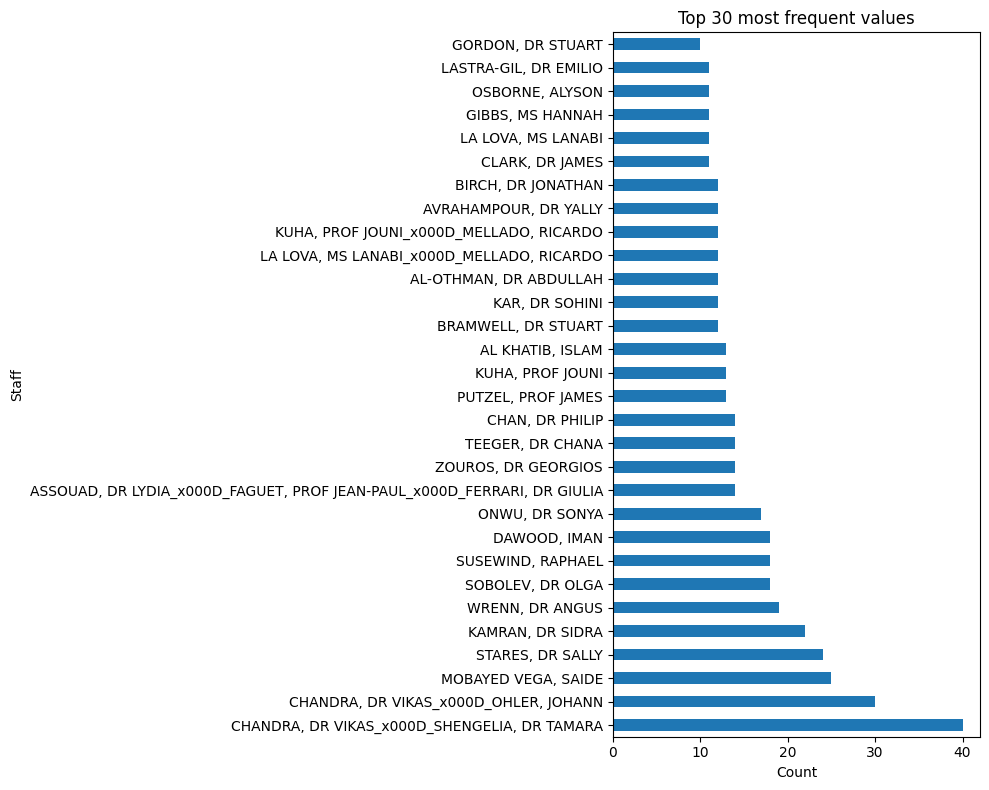

In [31]:
top_n = 30
counts.head(top_n).plot(kind='barh', figsize=(10, 8))
plt.xlabel('Count')
plt.title(f'Top {top_n} most frequent values')
plt.tight_layout()
plt.show()

In [23]:
staff_df = course_master_data[['Staff', 'Code']].copy()

staff_df['First Name'] = staff_df['Staff'].str.split(',').str[0].str.strip()
staff_df['Title'] = staff_df['Staff'].str.split(',').str[1].str.strip().str.split().str[0]
staff_df['Last Name'] = staff_df['Staff'].str.split(',').str[1].str.strip().str.split().str[1:].str.join(' ')

staff_df = staff_df.dropna().drop_duplicates()

staff_df.head()

,Staff,Code,First Name,Title,Last Name
0,"KAMATH, DR SAIPRIYA",AC102,KAMATH,DR,SAIPRIYA
1,"CONSTANTINOU, MRS CHRISOULLA",AC102.A,CONSTANTINOU,MRS,CHRISOULLA
9,"IRGASHEV, MR KHAMID",AC102.A,IRGASHEV,MR,KHAMID
11,"MCDERMOTT, MR THOMAS",AC102.A,MCDERMOTT,MR,THOMAS
14,"MCDONALD, MR PHILIP",AC102.A,MCDONALD,MR,PHILIP
